# 4. Missing data: does it matter how the gaps are filled?

Insulin is missing for 49% of the women and skinfold thickness for 30%. Milestone 1 filled every gap with the column's median, the simplest option. This notebook tests whether a smarter method does better (E08), then measures how much one woman's estimate depends on what was guessed for her (E09). It ends with a decision about the published model.

In [1]:
import sys, warnings
sys.path.insert(0, "..")          # so the notebook can import the project's src/ folder
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 4.1 Seven strategies, the same 50 splits

**What we're looking for.** Whether any way of handling the gaps scores better than the median fill from Milestone 1.

- Median fill (Milestone 1)
- Median fill + 'was missing' flags
- Nearest neighbours (10 most similar women)
- Iterative (predict each gap from the other columns)
- Iterative + 'was missing' flags
- Drop insulin and skinfold
- Gradient boosting (uses gaps directly)


,auc,auc_sd,brier
strategy,,,
Drop insulin and skinfold,0.838,0.027,0.156
Iterative + 'was missing' flags,0.837,0.027,0.156
Nearest neighbours (10 most similar women),0.837,0.027,0.157
Iterative (predict each gap from the other columns),0.836,0.027,0.157
Median fill (Milestone 1),0.835,0.027,0.157
Median fill + 'was missing' flags,0.832,0.027,0.158
Gradient boosting (uses gaps directly),0.823,0.028,0.164


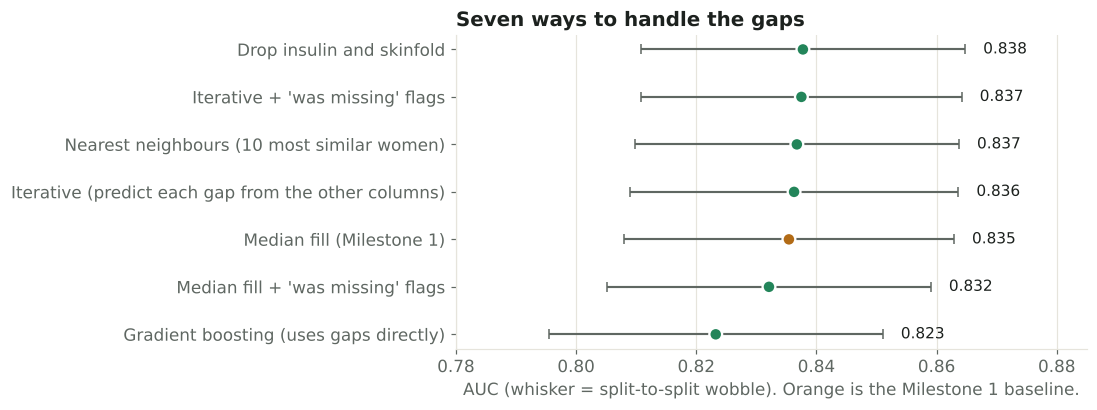

In [2]:
from src.data import load_data
from src.missing import compare_strategies, strategies
from src import figures

X, y = load_data()
for name in strategies():
    print("-", name)
table = compare_strategies(X, y)
display(table[["auc", "auc_sd", "brier"]].sort_values("auc", ascending=False))
figures.strategy_comparison();

**How to read it.** Each row is one way of dealing with the gaps. The first six all end in the same logistic regression, so only the gap handling differs. "Flags" adds a yes/no column saying a reading was missing. "Nearest neighbours" copies from the 10 most similar women. "Iterative" predicts each missing value from the woman's other measurements. `auc` is the average over 50 splits and `auc_sd` is how much it wobbles from split to split.

**What it means.** The six logistic versions land between 0.832 and 0.838. The wobble between splits is 0.027, about five times the whole range. Gradient boosting, which accepts gaps without any filling, is last at 0.823. Nothing clever beats the median, and leaving insulin and skinfold out entirely scores as well as anything (0.838).

**What's next and why.** Averages can hide a small but consistent edge, so compare each strategy with the baseline one split at a time.

## 4.2 Split by split against the baseline

**What we're looking for.** Whether any strategy beats the median fill consistently, even by a little.

In [3]:
paired = table[["auc_vs_baseline", "splits_better_than_baseline"]].drop(index="Median fill (Milestone 1)")
paired.sort_values("auc_vs_baseline", ascending=False)

,auc_vs_baseline,splits_better_than_baseline
strategy,,
Drop insulin and skinfold,0.002,0.760
Iterative + 'was missing' flags,0.002,0.720
Nearest neighbours (10 most similar women),0.001,0.640
Iterative (predict each gap from the other columns),0.001,0.680
Median fill + 'was missing' flags,-0.003,0.520
Gradient boosting (uses gaps directly),-0.012,0.280


**How to read it.** `auc_vs_baseline` is the average AUC gain over the median fill, measured on identical splits. `splits_better_than_baseline` is the share of the 50 splits where the strategy won (0.5 is a coin flip).

**What it means.** Dropping the two columns wins 76% of the splits, but by an average of 0.002, which nobody would notice in use. Adding "was missing" flags to the median fill is a coin flip (52%) and slightly worse on average. So the gaps carry no useful signal, which matches the weak link seen in notebook 1.

**What's next and why.** The model results say filling doesn't help. Check directly why: how well can a missing reading be guessed at all?

## 4.3 Can a missing reading be guessed back?

**What we're looking for.** The accuracy of each fill method, tested the only way possible: hide readings we do have, ask the method to guess them, and compare with the truth.

Insulin


,r2,typical_miss
Median,-0.081,79.713
Nearest neighbours,0.194,68.834
Iterative,0.286,65.289


SkinThickness


,r2,typical_miss
Median,-0.007,8.356
Nearest neighbours,0.363,6.474
Iterative,0.404,6.246


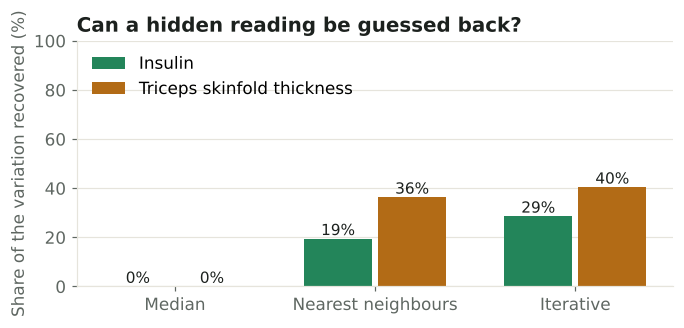

In [4]:
from src.missing import recovery_test
for col in ["Insulin", "SkinThickness"]:
    print(col)
    display(recovery_test(X, col))
figures.recovery();

**How to read it.** A quarter of the known readings are hidden, 20 times over. `r2` is the share of the real variation the guesses recover: 0 means no better than guessing the median for everyone, 1 would be perfect. `typical_miss` is the average distance between guess and truth, in the measurement's own units.

**What it means.** The best method recovers 29% of the variation in insulin and misses by 65 mu U/mL on average, against 80 for the plain median. Skinfold does a little better (40%, missing by 6 mm against 8). Insulin can't be reconstructed from the other measurements with any accuracy. Whatever goes into those 374 gaps is mostly noise, which explains why no fill method improved the model.

**What's next and why.** If the fills are mostly noise, a woman's estimate partly depends on the luck of the fill. Measure how much.

## 4.4 One woman, 30 plausible fills

**What we're looking for.** How far each woman's estimate moves when the gaps are filled 30 different plausible ways instead of one "best" way. This is called multiple imputation.

,women,median_width,p90_width
all readings present,392.000,3.189,9.154
insulin missing,374.000,5.317,9.857
insulin and skinfold missing,227.000,6.157,10.288


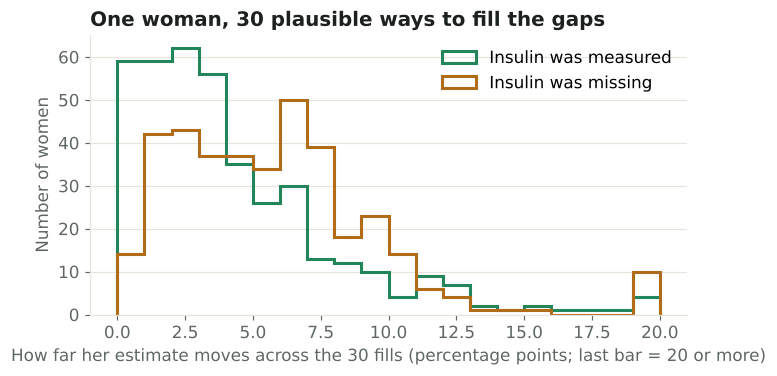

In [5]:
from src.missing import multiple_imputation, spread_summary
from src.evaluate import pick_threshold, out_of_fold
from src.modeling import logistic

draws = multiple_imputation(X, y)            # 768 women x 30 fills, every prediction held out
cut_m1 = pick_threshold(y, out_of_fold(logistic(), X, y))
spread = spread_summary(X, y, draws, cut_m1)
display(pd.DataFrame(spread["by_group"]).T[["women", "median_width", "p90_width"]])
figures.imputation_spread();

**How to read it.** For each woman, the width is the gap between her 5th and 95th percentile estimates across the 30 fills, in percentage points. `median_width` is the typical woman in the group and `p90_width` is one of the widest 10%. The chart counts women at each width; the last bar collects 20 and over.

**What it means.** A woman with no insulin reading typically moves 5.3 points across the fills, and one in ten moves about 10. Women with every reading still move 3.2 points, because the model itself was trained on filled-in data and shifts with each fill. So a single estimate such as "31%" hides a spread of several points that comes purely from guesswork.

**What's next and why.** A few points only matters if it changes the decision, so count the women who cross the cut-off.

## 4.5 Who lands on both sides of the cut-off?

**What we're looking for.** Women who are flagged under some fills and cleared under others.

In [6]:
print(f"Cut-off {spread['threshold']:.2f}, {spread['draws']} fills")
display(pd.DataFrame(spread["by_group"]).T[["women", "flips", "flip_share"]])
print(f"Women whose decision depends on the fill: {spread['flips_total']} of {len(y)}")

Cut-off 0.24, 30 fills


,women,flips,flip_share
all readings present,392.000,23.000,0.059
insulin missing,374.000,30.000,0.080
insulin and skinfold missing,227.000,20.000,0.088


Women whose decision depends on the fill: 53 of 768


**How to read it.** A woman counts as a flip if she is flagged in more than 10% but fewer than 90% of the fills. `flip_share` is the share of the group that flips.

**What it means.** 53 of 768 women (7%) get a different screening decision depending on which plausible fill is used: 8% of those with insulin missing and 6% of those with every reading. For those women the outcome is set by the fill, not by anything measured.

**What's next and why.** Put the evidence together and decide what the published model should do.

## 4.6 Decision: leave insulin and skinfold out

**What we're looking for.** The results for a six-input model with insulin and skinfold removed, set against the eight-input baseline from notebook 3.

In [7]:
from src.evaluate import summarise
from src.modeling import current_features, LEFT_OUT
from src.data import FEATURES

cols = current_features(FEATURES)
print("Left out:", LEFT_OUT)
print("Women who still have a gap in the six remaining inputs:", int(X[cols].isna().any(axis=1).sum()))

def row(s):
    t = s["threshold_screening"]
    return {"inputs": len(s["features"]), "AUC": s["oof_auc"], "cut-off": t["threshold"],
            "cases caught": t["tp"], "missed": t["fn"], "false alarms": t["fp"],
            "calibration slope": s["calibration"]["slope"],
            "cleared, age 45+": s["by_age"][2]["specificity"]}

base = summarise(X, y, out_of_fold(logistic(), X, y))
six = summarise(X[cols], y, out_of_fold(logistic(), X[cols], y))
pd.DataFrame([row(base), row(six)], index=["Milestone 1 (eight inputs)", "Milestone 2 (six inputs)"]).T

Left out: ['Insulin', 'SkinThickness']
Women who still have a gap in the six remaining inputs: 44


,Milestone 1 (eight inputs),Milestone 2 (six inputs)
inputs,8.000,6.000
AUC,0.836,0.838
cut-off,0.240,0.230
cases caught,229.000,231.000
missed,39.000,37.000
false alarms,188.000,194.000
calibration slope,0.959,0.971
"cleared, age 45+",0.224,0.224


**How to read it.** Two models side by side, each scored on predictions for women it had not seen. The cut-off is re-chosen for each so that at least 85% of true cases are caught.

**What it means.** The six-input model matches the baseline on every line: AUC 0.838 against 0.836, 231 cases caught against 229, and 194 false alarms against 188. The gaps fall from 374 women to 44, so almost nobody's estimate rests on a filled-in value any more. The decision (D09) is to publish the six-input model: it is as accurate, it stops inventing half a column, and it asks for two fewer measurements. What it does not fix is the weak result for women 45 and over, where only 22% of healthy women are cleared (B10).

**What's next and why.** Milestone 3 lets effects bend and interact. Insulin gets one more hearing there, in the form where it should matter most: combined with glucose as a rough measure of insulin resistance (E29). The same milestone goes after B10.